<a href="https://colab.research.google.com/github/alessiomodonesi/Python-Exercises/blob/main/AI_MSc/lab2/Lab2_solutions_partial.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 2

This notebook has two parts:
- **Part 1 — Search algorithms**: uninformed search, informed search and local search;
- **Part 2 — Adversarial search**: Tic-Tac-Toe with Minimax and Monte Carlo Tree Search.


# Search Algorithms

**Contents**
1. Problem and node
2. The map of Romania
3. Uninformed search (BFS, DFS, uniform cost)
4. Informed search (greedy, A\*)
5. Local search (hill climbing, simulated annealing)


In [1]:
# Standard libraries + matplotlib and networkx
import math, random, heapq, time
from collections import deque
import matplotlib.pyplot as plt
import networkx as nx

random.seed(42)

## 1. Problem and node

A **search problem** is defined by:
- an **initial state**;
- the **actions** available in each state;
- the **transition model** `result(state, action)`;
- the **goal test**;
- the **cost** of each step.

A **node** of the search tree contains a state, the parent node, the action that generated it and the path cost `g(n)` from the root.

In [2]:
class Problem:
    "Abstract class: subclasses override actions, result and (if needed) h."
    def __init__(self, initial, goal=None):
        self.initial, self.goal = initial, goal

    def actions(self, state):            raise NotImplementedError
    def result(self, state, action):     raise NotImplementedError
    def goal_test(self, state):          return state == self.goal
    def path_cost(self, c, s1, a, s2):   return c + 1          # unit step cost by default
    def h(self, node):                   return 0              # heuristic (0 = no information)


class Node:
    def __init__(self, state, parent=None, action=None, path_cost=0):
        self.state, self.parent, self.action, self.path_cost = state, parent, action, path_cost
        self.depth = parent.depth + 1 if parent else 0

    def expand(self, problem):
        "Return the child nodes."
        return [self.child(problem, a) for a in problem.actions(self.state)]

    def child(self, problem, action):
        s2 = problem.result(self.state, action)
        return Node(s2, self, action, problem.path_cost(self.path_cost, self.state, action, s2))

    def path(self):
        "List of nodes from the root to this node."
        node, out = self, []
        while node:
            out.append(node)
            node = node.parent
        return out[::-1]

    def solution(self):
        "Sequence of actions from the root to this node."
        return [n.action for n in self.path()[1:]]

    def __lt__(self, other):   # needed by heapq to break ties
        return self.state < other.state

    def __repr__(self):
        return f"<Node {self.state}>"

## 2. The map of Romania

The classic problem from the book: going from **Arad** to **Bucharest**. The graph is undirected; each edge is weighted by the road distance. The coordinates are used to draw the map and for the heuristic (straight-line distance).

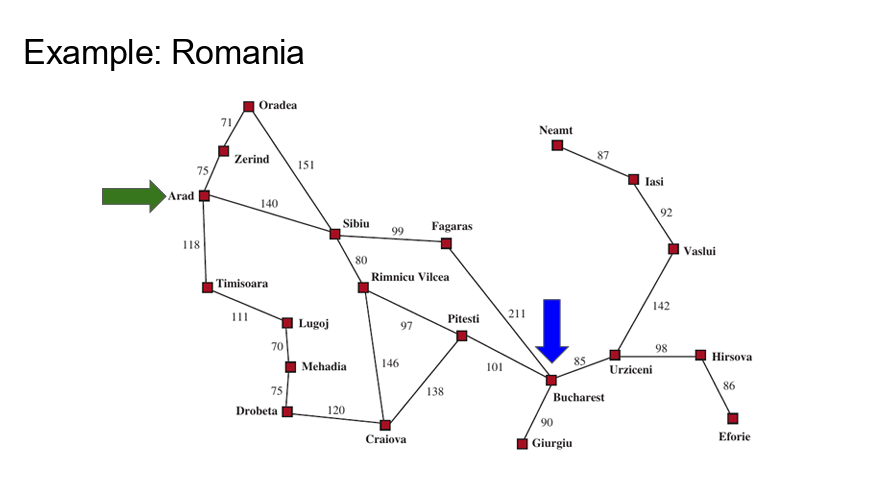

In [3]:
roads = dict(
    Arad=dict(Zerind=75, Sibiu=140, Timisoara=118),
    Bucharest=dict(Urziceni=85, Pitesti=101, Giurgiu=90, Fagaras=211),
    Craiova=dict(Drobeta=120, Rimnicu=146, Pitesti=138),
    Drobeta=dict(Mehadia=75),
    Eforie=dict(Hirsova=86),
    Fagaras=dict(Sibiu=99),
    Hirsova=dict(Urziceni=98),
    Iasi=dict(Vaslui=92, Neamt=87),
    Lugoj=dict(Timisoara=111, Mehadia=70),
    Oradea=dict(Zerind=71, Sibiu=151),
    Pitesti=dict(Rimnicu=97),
    Rimnicu=dict(Sibiu=80),
    Urziceni=dict(Vaslui=142))

# undirected, weighted networkx graph
romania = nx.Graph()
for a, nbrs in roads.items():
    for b, d in nbrs.items():
        romania.add_edge(a, b, weight=d) # Create nodes a and b if they don't exist yet, and add an edge between them with weight d

locations = dict(
    Arad=(91, 492), Bucharest=(400, 327), Craiova=(253, 288),
    Drobeta=(165, 299), Eforie=(562, 293), Fagaras=(305, 449),
    Giurgiu=(375, 270), Hirsova=(534, 350), Iasi=(473, 506),
    Lugoj=(165, 379), Mehadia=(168, 339), Neamt=(406, 537),
    Oradea=(131, 571), Pitesti=(320, 368), Rimnicu=(233, 410),
    Sibiu=(207, 457), Timisoara=(94, 410), Urziceni=(456, 350),
    Vaslui=(509, 444), Zerind=(108, 531))

nx.set_node_attributes(romania, locations, "pos")   # position stored as a node attribute

print(romania.number_of_nodes(), "cities,", romania.number_of_edges(), "roads")
print("Neighbors of Arad:", {v: romania["Arad"][v]["weight"] for v in romania.neighbors("Arad")})

20 cities, 23 roads
Neighbors of Arad: {'Zerind': 75, 'Sibiu': 140, 'Timisoara': 118}


In [4]:
class GraphProblem(Problem):
    "Find a path between two nodes of a weighted networkx graph ('weight' attribute)."
    def __init__(self, initial, goal, graph):
        super().__init__(initial, goal)
        self.graph = graph

    def actions(self, state):          return list(self.graph.neighbors(state))   # action = city to move to
    def result(self, state, action):   return action
    def path_cost(self, c, s1, a, s2): return c + self.graph[s1][s2]["weight"]

    def h(self, node):
        "Straight-line distance to the goal (from the 'pos' attributes)."
        pos = nx.get_node_attributes(self.graph, "pos")
        if not pos:
            return 0
        (x1, y1), (x2, y2) = pos[node.state], pos[self.goal]
        return math.hypot(x1 - x2, y1 - y2)

romania_problem = GraphProblem("Arad", "Bucharest", romania)

Drawing with `networkx`: **orange** = explored nodes, **green** = path found.

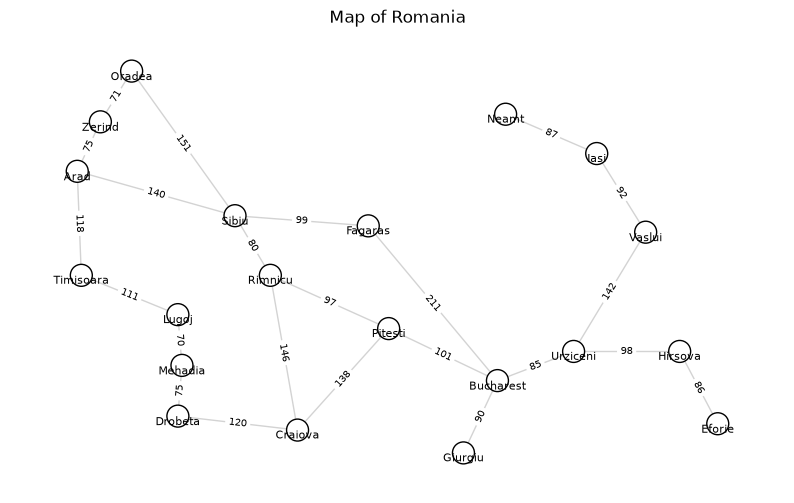

In [5]:
def draw_map(explored=(), path=(), title="Map of Romania", G=romania):
    pos = nx.get_node_attributes(G, "pos")
    path_edges = list(zip(path, path[1:]))
    colors = ["limegreen" if v in path else "orange" if v in explored else "white" for v in G.nodes]

    plt.figure(figsize=(10, 6))
    nx.draw_networkx_edges(G, pos, edge_color="lightgray")
    nx.draw_networkx_edges(G, pos, edgelist=path_edges, edge_color="green", width=3)
    nx.draw_networkx_edge_labels(G, pos, edge_labels=nx.get_edge_attributes(G, "weight"), font_size=7)
    nx.draw_networkx_nodes(G, pos, node_color=colors, edgecolors="black", node_size=250)
    nx.draw_networkx_labels(G, pos, labels={v: v for v in G}, font_size=8,
                            verticalalignment="top", horizontalalignment="center")
    plt.title(title); plt.axis("off"); plt.show()

draw_map()

## 3. Uninformed search

All the following algorithms return `(solution_node, explored_set)`, so we can compare and draw them.

| Algorithm | Frontier | Complete | Optimal |
|---|---|---|---|
| Breadth-first (BFS) | FIFO queue | yes | yes, if step costs are equal |
| Depth-first (DFS) | LIFO stack | no (in general) | no |
| Uniform cost (UCS) | priority queue on `g(n)` | yes | yes |

### Exercise 1: Implement BFS and DFS

Complete the two functions in the cell below. Each one must return a pair `(solution_node, visited)`:
- `solution_node` is the `Node` that contains the goal state (or `None` if there is no solution);
- `visited` is the set of states already seen during the search.

**Steps**
0. Delete the `raise NotImplementedError(...)` line at the top of the function.
1. Create the frontier containing only the root node `Node(problem.initial)`.
2. Create the set `visited` containing the initial state.
3. While the frontier is not empty:
   - take a node out of the frontier;
   - if it is the goal (`problem.goal_test(node.state)`), return it together with `visited`;
   - otherwise, for each child in `node.expand(problem)`: if its state has not been seen yet, add the state to `visited` and the child to the frontier.
4. If the frontier becomes empty, return `None, visited`.

**Hints**
- The only difference between BFS and DFS is **which node you take out** of the frontier.
- BFS uses a **FIFO queue**: `deque([...])`, add with `append()`, remove with `popleft()` (the oldest node).
- DFS uses a **LIFO stack**: a plain list, add with `append()`, remove with `pop()` (the newest node).
- Mark a state as visited **when you add it to the frontier**, not when you take it out: this way the same state is never added twice.

When you are done, test your code with `report("Breadth-first", breadth_first_search, romania_problem)` after running the cell with the `report` function below. BFS should find `Arad → Sibiu → Fagaras → Bucharest`.

In [6]:
def breadth_first_search(problem):
    raise NotImplementedError("Complete breadth_first_search")   # TODO: delete this line
    frontier = ...      # TODO: FIFO queue containing the root node
    visited = ...       # TODO: set containing the initial state
    while frontier:
        node = ...      # TODO: take the OLDEST node
        # TODO: if node is the goal, return node, visited
        # TODO: for each child of node, if its state is not in visited,
        #       add the state to visited and the child to the frontier
    return None, visited


def depth_first_search(problem):
    raise NotImplementedError("Complete depth_first_search")     # TODO: delete this line
    frontier = ...      # TODO: LIFO stack (a list) containing the root node
    visited = ...       # TODO: set containing the initial state
    while frontier:
        node = ...      # TODO: take the NEWEST node
        # TODO: same steps as in BFS
    return None, visited

### Solution

In [7]:
def breadth_first_search(problem):
    frontier = deque([Node(problem.initial)])   # FIFO queue: first in, first out
    visited = {problem.initial}                  # states already seen
    while frontier:
        node = frontier.popleft()                # take the OLDEST node
        if problem.goal_test(node.state):
            return node, visited
        for child in node.expand(problem):
            if child.state not in visited:
                visited.add(child.state)
                frontier.append(child)
    return None, visited


def depth_first_search(problem):
    frontier = [Node(problem.initial)]           # LIFO stack: last in, first out
    visited = {problem.initial}                  # states already seen
    while frontier:
        node = frontier.pop()                    # take the NEWEST node
        if problem.goal_test(node.state):
            return node, visited
        for child in node.expand(problem):
            if child.state not in visited:
                visited.add(child.state)
                frontier.append(child)
    return None, visited

### Exercise 2: Implement best-first search and uniform cost search

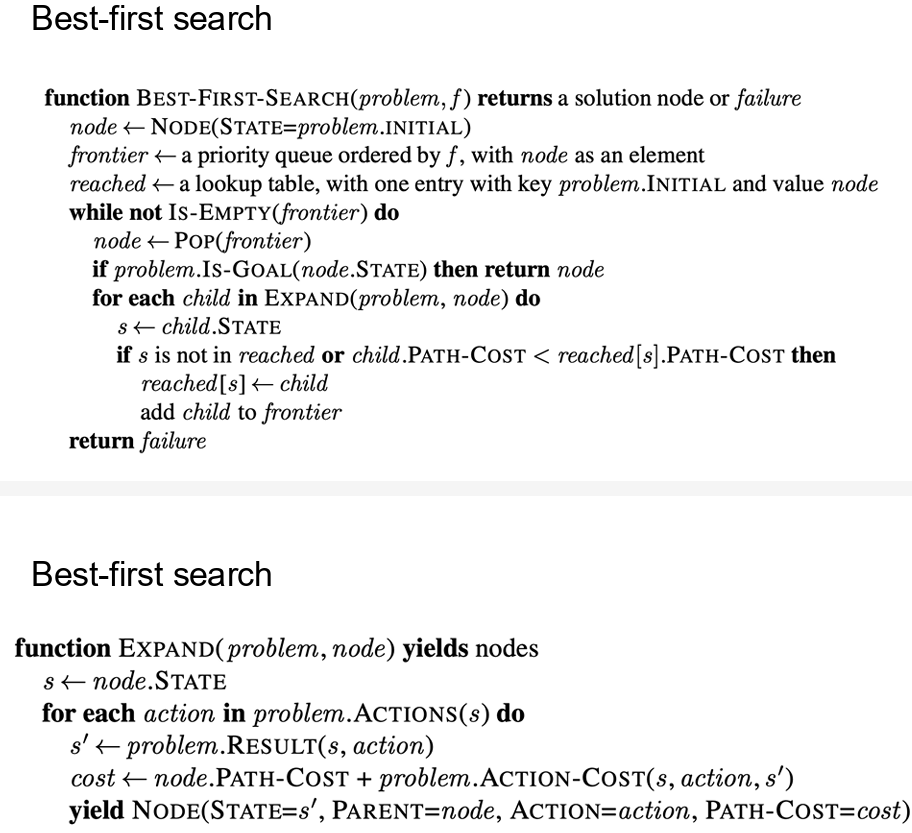

**Best-first search** always expands the node with the **lowest value of an evaluation function `f(n)`**. Changing `f` gives different algorithms:
- `f(n) = g(n)` (the path cost) → **uniform cost search**;
- `f(n) = h(n)` → greedy best-first;
- `f(n) = g(n) + h(n)` → A\*.

Complete the two functions in the cell below. `best_first_search` must return a pair `(solution_node, explored)`:
- `solution_node` is the `Node` that contains the goal state (or `None` if there is no solution);
- `explored` is the set of states already **expanded**.

**Steps**
0. Delete the `raise NotImplementedError(...)` line at the top of the function.
1. Create the root node `Node(problem.initial)` and a frontier containing the pair `(f(root), root)`.
2. Create an empty set `explored`.
3. While the frontier is not empty:
   - take out the pair with the lowest `f`;
   - if its state is already in `explored`, skip it (`continue`);
   - if it is the goal, return it together with `explored`;
   - otherwise add its state to `explored` and, for each child whose state is not in `explored`, add `(f(child), child)` to the frontier.
4. If the frontier becomes empty, return `None, explored`.

Then write `uniform_cost_search` in **one line**, by calling `best_first_search` with the right `f`.

**Hints**
- The frontier is a **priority queue**: use a plain list with `heapq.heappush(frontier, (priority, node))` to add and `heapq.heappop(frontier)` to take out the pair with the **lowest** priority.
- `heappop` returns the whole pair: unpack it with `f_value, node = heapq.heappop(frontier)`.
- `f` is a function: call it as `f(node)`. Use `lambda n: ...` to write it in one line; the path cost of a node is `n.path_cost`.
- The same state may enter the frontier more than once with different costs. The cheapest copy comes out first; the others are skipped because their state is already in `explored`.
- Unlike BFS, the goal test is done when the node is **taken out** of the frontier: otherwise the path found might not be the cheapest.

When you are done, test your code with `report("Uniform cost", uniform_cost_search, romania_problem)` after running the cell with the `report` function below. It should find `Arad → Sibiu → Rimnicu → Pitesti → Bucharest` with cost 418.

In [8]:
def best_first_search(problem, f):
    raise NotImplementedError("Complete best_first_search")   # TODO: delete this line
    root = ...          # TODO: root node
    frontier = ...      # TODO: list containing the pair (f(root), root)
    explored = ...      # TODO: empty set
    while frontier:
        f_value, node = ...   # TODO: take out the pair with the LOWEST f
        # TODO: if node.state is already in explored, skip it
        # TODO: if node is the goal, return node, explored
        # TODO: add node.state to explored
        # TODO: for each child whose state is not in explored,
        #       push (f(child), child) into the frontier
    return None, explored


def uniform_cost_search(problem):
    return best_first_search(problem, ...)   # f(n) = g(n), the path cost

### Solution

In [9]:
def best_first_search(problem, f):
    "Best-first graph search: always expands the node with the lowest f."
    root = Node(problem.initial)
    frontier = [(f(root), root)]             # priority queue ordered by f
    explored = set()                         # states already expanded
    while frontier:
        f_value, node = heapq.heappop(frontier)    # take the node with the LOWEST f
        if node.state in explored:           # already expanded via a better path: skip it
            continue
        if problem.goal_test(node.state):
            return node, explored
        explored.add(node.state)
        for child in node.expand(problem):
            if child.state not in explored:
                heapq.heappush(frontier, (f(child), child))
    return None, explored


def uniform_cost_search(problem):
    return best_first_search(problem, lambda n: n.path_cost)        # f(n) = g(n), the path cost

Let's try the four algorithms on Arad → Bucharest and compare **path**, **cost** and **number of explored nodes**.

In [10]:
def report(name, algorithm, problem):
    node, explored = algorithm(problem)
    path = [n.state for n in node.path()]
    print(f"{name:<28} cost={node.path_cost:>4.0f}  explored={len(explored):>2}  {' → '.join(path)}")
    return node, explored

for name, alg in [("Breadth-first", breadth_first_search),
                  ("Depth-first", depth_first_search),
                  ("Uniform cost", uniform_cost_search)]:
    report(name, alg, romania_problem)

Breadth-first                cost= 450  explored=12  Arad → Sibiu → Fagaras → Bucharest
Depth-first                  cost= 733  explored=11  Arad → Timisoara → Lugoj → Mehadia → Drobeta → Craiova → Pitesti → Bucharest
Uniform cost                 cost= 418  explored=12  Arad → Sibiu → Rimnicu → Pitesti → Bucharest


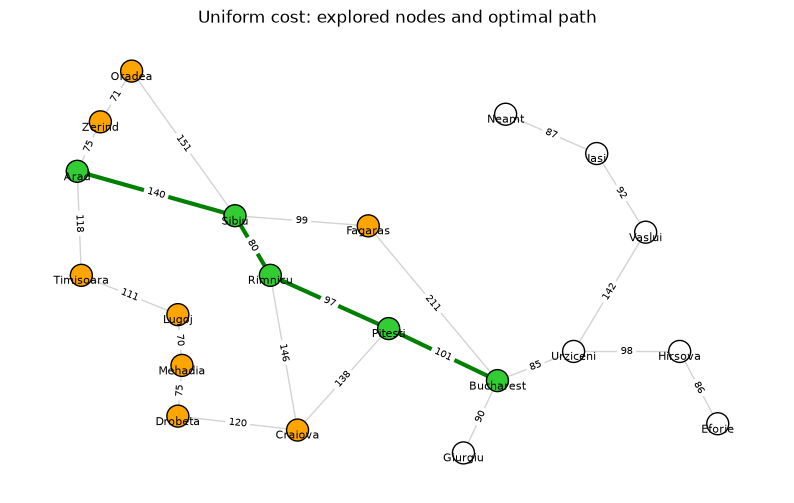

In [11]:
node, explored = uniform_cost_search(romania_problem)
draw_map(explored, [n.state for n in node.path()], "Uniform cost: explored nodes and optimal path")

## 4. Informed search

We use a **heuristic** `h(n)` = straight-line distance from `n` to Bucharest.

- **Greedy best-first**: `f(n) = h(n)` — fast but not optimal.
- **A\***: `f(n) = g(n) + h(n)` — optimal if `h` is admissible (never overestimates)

> **Note:** greedy best-first and A\* reuse the same `best_first_search` written for uniform cost search: the implementation never changes, only the lambda function passed as `f` does.
> - uniform cost: `lambda n: n.path_cost`
> - greedy: `lambda n: h(n)`
> - A\*: `lambda n: n.path_cost + h(n)`

In [12]:
def greedy_best_first_search(problem, h=None):
    h = h or problem.h
    return best_first_search(problem, lambda n: h(n))


def astar_search(problem, h=None):
    h = h or problem.h
    return best_first_search(problem, lambda n: n.path_cost + h(n))


Greedy best-first            cost= 450  explored= 3  Arad → Sibiu → Fagaras → Bucharest
A*                           cost= 418  explored= 5  Arad → Sibiu → Rimnicu → Pitesti → Bucharest


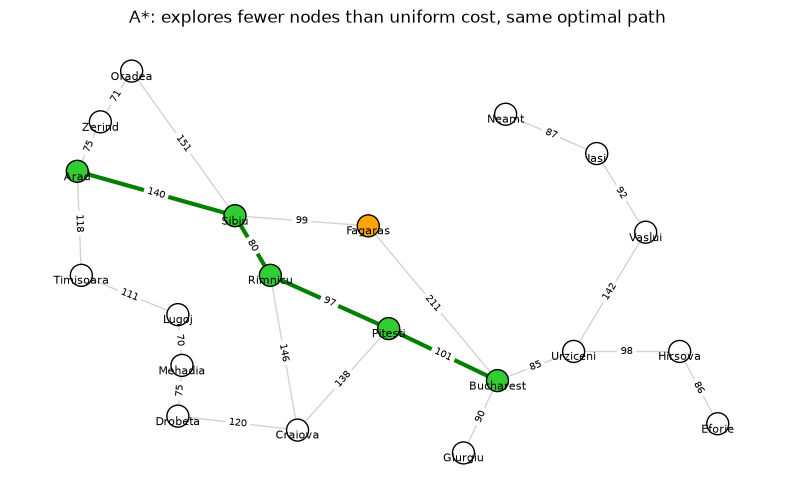

In [13]:
for name, alg in [("Greedy best-first", greedy_best_first_search),
                  ("A*", astar_search)]:
    report(name, alg, romania_problem)

node, explored = astar_search(romania_problem)
draw_map(explored, [n.state for n in node.path()], "A*: explores fewer nodes than uniform cost, same optimal path")

Note: **greedy** finds a path (via Fagaras) that is more expensive than the optimal one (via Rimnicu and Pitesti, cost 418), while **A\*** finds the optimal one exploring fewer nodes than uniform cost.

### Step-by-step visualization

The animation below shows **every step** of a search algorithm on the map of Romania. Use the **play / pause** buttons or the slider to move between steps.

- 🔴 **red**: the node being expanded (the red edges show its path from Arad);
- 🔵 **blue**: the frontier;
- 🟠 **orange**: the explored nodes;
- 🟢 **green**: the solution path, when the goal is reached.

Under the map you can read the frontier at each step: for uniform cost, greedy and A\* it is sorted by `f`, so the first node is the next one to be expanded. Notice that the same city can appear more than once in the frontier with different values of `f`.

Change `ALGORITHM` to compare: `"BFS"`, `"DFS"`, `"Uniform cost"`, `"Greedy"`, `"A*"`.

In [14]:
from matplotlib import animation
from IPython.display import HTML

def trace_search(problem, algorithm):
    "Run a search algorithm and record a snapshot of the frontier at every step."
    h = problem.h
    f = {"BFS": None, "DFS": None,
         "Uniform cost": lambda n: n.path_cost,
         "Greedy": lambda n: h(n),
         "A*": lambda n: n.path_cost + h(n)}[algorithm]
    root = Node(problem.initial)
    frontier = [(f(root) if f else 0, root)]
    visited, explored, steps = {root.state}, [], []
    while frontier:
        if algorithm == "BFS":
            _, node = frontier.pop(0)                 # oldest node
        elif algorithm == "DFS":
            _, node = frontier.pop()                  # newest node
        else:
            _, node = heapq.heappop(frontier)         # lowest f
            if node.state in explored:
                continue
        steps.append(dict(node=node, frontier=sorted(frontier, key=lambda p: p[0]) if f else list(frontier),
                          explored=list(explored), goal=problem.goal_test(node.state)))
        if problem.goal_test(node.state):
            return steps
        explored.append(node.state)
        for child in node.expand(problem):
            if f is None:                             # BFS / DFS
                if child.state not in visited:
                    visited.add(child.state)
                    frontier.append((0, child))
            elif child.state not in explored:         # best-first
                heapq.heappush(frontier, (f(child), child))
    return steps


def animate_search(problem, algorithm, G=romania, interval=1500):
    "Interactive step-by-step animation (play / pause / slider)."
    steps = trace_search(problem, algorithm)
    pos = nx.get_node_attributes(G, "pos")
    fig, ax = plt.subplots(figsize=(9, 6), dpi=72)
    plt.close(fig)                                    # show only the animation, not a static figure
    legend = [plt.Line2D([], [], marker="o", ls="", markeredgecolor="black", markerfacecolor=c, label=l)
              for c, l in [("red", "expanding"), ("lightskyblue", "frontier"),
                           ("orange", "explored"), ("limegreen", "solution")]]

    def draw(i):
        ax.clear()
        s = steps[i]
        path = [n.state for n in s["node"].path()]
        front = [n.state for _, n in s["frontier"]]
        colors = []
        for v in G.nodes:
            if s["goal"] and v in path: colors.append("limegreen")    # solution path
            elif v == s["node"].state:  colors.append("red")          # node being expanded
            elif v in front:            colors.append("lightskyblue") # frontier
            elif v in s["explored"]:    colors.append("orange")       # explored
            else:                       colors.append("white")
        nx.draw_networkx_edges(G, pos, ax=ax, edge_color="lightgray")
        nx.draw_networkx_edges(G, pos, ax=ax, edgelist=list(zip(path, path[1:])),
                               edge_color="green" if s["goal"] else "red", width=3)
        nx.draw_networkx_edge_labels(G, pos, ax=ax, edge_labels=nx.get_edge_attributes(G, "weight"), font_size=7)
        nx.draw_networkx_nodes(G, pos, ax=ax, node_color=colors, edgecolors="black", node_size=250)
        nx.draw_networkx_labels(G, pos, ax=ax, font_size=8, verticalalignment="top")
        n = s["node"]
        action = "GOAL reached!" if s["goal"] else "expanding"
        ax.set_title(f"{algorithm} — step {i + 1}/{len(steps)}: {action} {n.state}  (g = {n.path_cost:.0f})")
        if algorithm in ("BFS", "DFS"):
            ftxt = "Frontier: " + ", ".join(front)
        else:
            ftxt = "Frontier, sorted by f: " + ", ".join(f"{m.state}({p:.0f})" for p, m in s["frontier"])
        ax.text(0.0, -0.06, ftxt, transform=ax.transAxes, fontsize=8, wrap=True)
        ax.legend(handles=legend, loc="lower right", fontsize=8)
        ax.axis("off")

    anim = animation.FuncAnimation(fig, draw, frames=len(steps), interval=interval)
    html = anim.to_jshtml(default_mode="once")       # play once and stop at the last step
    html = html.replace('class="anim-state"', 'class="anim-state" style="display:none"')   # hide Once / Loop / Reflect
    return HTML(html)

In [15]:
ALGORITHM = "A*"      # try: "BFS", "DFS", "Uniform cost", "Greedy", "A*"
animate_search(romania_problem, ALGORITHM)